# Analítica Empresarial Integrada — Laboratorio D13
## Semana 13 · Gobierno de Datos y Cumplimiento Normativo
**TECSUP 2026-II**
* Estudiante: Trilce Aranda
* Docente: Pilar Rocío Sayán Mejía**


### Auditoría de un modelo
**Sesgo por subgrupos + explicabilidad con SHAP + checklist de gobierno/cumplimiento**

Caso reproducible: **UCI Adult (ID 2)**.

> Las variables sensibles se usan para **auditoría**, no para recomendar decisiones discriminatorias.  
> SHAP explica el comportamiento del modelo; **no demuestra causalidad**.

In [1]:
# Instala en Colab las librerías que no vienen por defecto (cliente de UCI, SHAP y Plotly)
%pip install -q ucimlrepo shap plotly

In [2]:
# Se silencian las advertencias de las librerías para leer mejor los resultados
import warnings
warnings.filterwarnings("ignore")
# pandas y numpy para los datos, Plotly y matplotlib para graficar
import numpy as np, pandas as pd
import plotly.express as px
import matplotlib.pyplot as plt
# ucimlrepo descarga el conjunto de datos desde UCI
from ucimlrepo import fetch_ucirepo
# scikit-learn: partición, preprocesamiento, modelo y métricas
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
# SHAP explica cuánto aporta cada variable a una predicción
import shap
# Permite ver hasta 100 columnas al imprimir tablas
pd.set_option("display.max_columns", 100)

# 1. Fuente, ficha y linaje

In [3]:
# UCI Adult (ID 2): variables de personas y si su ingreso supera 50 000 dólares al año
adult = fetch_ucirepo(id=2)
# X_raw son las variables; y_raw es la variable objetivo
X_raw = adult.data.features.copy()
y_raw = adult.data.targets.copy()

# Trazabilidad: nombre, identificador y dimensiones de la fuente
print("Dataset:", adult.metadata.name)
print("UCI ID: 2")
print("X:", X_raw.shape, "y:", y_raw.shape)
display(X_raw.head())
display(y_raw.head())

Dataset: Adult
UCI ID: 2
X: (48842, 14) y: (48842, 1)


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba


,income
0,<=50K
1,<=50K
2,<=50K
3,<=50K
4,<=50K


In [4]:
# Limpia el texto: quita espacios y convierte los signos '?' en valores faltantes
def clean_str(s):
    s = s.astype("string").str.strip().replace({"?": pd.NA, "nan": pd.NA})
    return s.astype(object).where(s.notna(), np.nan)

# Se trabaja sobre una copia para conservar los datos originales
X = X_raw.copy()
for c in X.select_dtypes(include=["object","string"]).columns:
    X[c] = clean_str(X[c])

# Variable objetivo: 1 si el ingreso es mayor de 50K, 0 en caso contrario
target = y_raw.iloc[:,0].astype("string").str.strip().str.replace(".", "", regex=False)
y = target.str.contains(">50K", regex=False).astype(int)

# Proporción de cada clase: la clase positiva es minoritaria
print(y.value_counts(normalize=True).rename("proportion"))
# Calidad: cuántos valores faltantes tiene cada variable
print("Nulos por variable:")
display(X.isna().sum().sort_values(ascending=False).head(15))

income
0    0.760718
1    0.239282
Name: proportion, dtype: float64
Nulos por variable:


,0
occupation,2809
workclass,2799
native-country,857
education,0
fnlwgt,0
age,0
marital-status,0
education-num,0
race,0
relationship,0


### Ficha de gobierno

- **Fuente:** UCI Machine Learning Repository, conjunto de datos Adult (ID 2), que contiene información demográfica, laboral y económica de personas.

- **Finalidad académica:** Analizar y evaluar un modelo de clasificación que predice si los ingresos anuales de una persona superan los 50 000 dólares, revisando su desempeño y posibles diferencias entre grupos.

- **Variable objetivo:** `income`. Indica si el ingreso anual de una persona es mayor a 50 000 dólares (>50K) o menor o igual a 50 000 dólares (<=50K).

- **Propietario/responsable propuesto:** El equipo de analítica de datos, encargado de administrar la información, documentar el modelo, evaluar sus resultados y supervisar su uso responsable.

- **Variables sensibles usadas solo para auditoría:** `sex` (sexo) y `race` (raza). Se utilizan para identificar posibles diferencias en las predicciones entre grupos y detectar posibles sesgos, no para tomar decisiones discriminatorias.

- **Reglas de calidad:**
  - Eliminar espacios innecesarios en los datos de texto.
  - Identificar los valores faltantes representados por el símbolo `?`.
  - Tratar los valores faltantes mediante técnicas de imputación.
  - Verificar que la variable objetivo esté correctamente clasificada en 0 y 1.
  - Comprobar que las variables tengan el tipo de dato correcto.
  - Conservar los datos originales para mantener la trazabilidad.

- **Linaje:** Fuente UCI Adult → limpieza de datos → partición de entrenamiento y prueba → transformación de variables → entrenamiento del modelo → generación de predicciones → auditoría de resultados y evaluación de posibles sesgos.

### Pregunta 1

¿Qué información del origen y significado de los datos debería conocer un responsable antes de aprobar el uso del modelo?

**Respuesta:**

El responsable debe conocer de dónde provienen los datos, quién los proporciona, qué información contienen y qué significa cada variable. También debe verificar si los datos están completos, si tienen valores faltantes y si son confiables. Esto permite saber si la información es adecuada para entrenar el modelo y si puede utilizarse de manera responsable.

### Pregunta 2

¿Qué diferencia existe entre tener un archivo de datos y tener datos gobernados?

**Respuesta:**

Tener un archivo de datos significa simplemente contar con información almacenada. En cambio, tener datos gobernados significa que esa información está organizada, documentada y cuenta con reglas de calidad, responsables y controles de seguridad. De esta manera, se conoce su origen, cómo debe utilizarse y quién es responsable de mantenerla.

# 2. Separación de variables sensibles para auditoría

In [5]:
# Busca una columna aunque cambie la forma de escribir su nombre
def find_col(cols, candidates):
    low={str(c).lower().replace("-","").replace("_","").replace(" ",""):c for c in cols}
    for x in candidates:
        k=x.lower().replace("-","").replace("_","").replace(" ","")
        if k in low: return low[k]
    return None

# Variables sensibles: se usan solo para auditar, no para entrenar
sex_col = find_col(X.columns, ["sex"])
race_col = find_col(X.columns, ["race"])
print("sex:", sex_col, "| race:", race_col)

# Tabla de auditoría con sexo y raza de cada persona
audit = pd.DataFrame(index=X.index)
audit["sex"] = X[sex_col].astype("string").fillna("Missing") if sex_col else "Unavailable"
audit["race"] = X[race_col].astype("string").fillna("Missing") if race_col else "Unavailable"

# Se retiran las variables sensibles de las que entrenan el modelo
drop_sensitive = [c for c in [sex_col, race_col] if c is not None]
X_model = X.drop(columns=drop_sensitive).copy()
# Número de variables que ve el modelo
print("Variables del modelo:", X_model.shape[1])

sex: sex | race: race
Variables del modelo: 12


### Pregunta 3

¿Por qué excluir una variable sensible del entrenamiento no garantiza por sí solo ausencia de sesgo?

**Respuesta:**

Porque, aunque se eliminen variables como el sexo y la raza, el modelo puede utilizar otras variables que estén relacionadas con ellas, como la ocupación, el nivel educativo o el lugar de residencia. De esta manera, puede seguir identificando indirectamente características de ciertos grupos y generar resultados diferentes o injustos. Por eso, es importante evaluar las predicciones por subgrupos para detectar posibles sesgos.

# 3. Train/test y modelo base

In [6]:
# Partición 75 % / 25 % estratificada por la variable objetivo; la semilla fija repite el resultado
idx_train, idx_test = train_test_split(
    X_model.index, test_size=0.25, random_state=42, stratify=y
)
# Se separan variables y objetivo de entrenamiento y de prueba
X_train, X_test = X_model.loc[idx_train], X_model.loc[idx_test]
y_train, y_test = y.loc[idx_train], y.loc[idx_test]
# La auditoría usa solo las personas de la muestra de prueba
audit_test = audit.loc[idx_test].copy()

# Variables numéricas y categóricas se tratan por separado
num_cols = X_model.select_dtypes(include=np.number).columns.tolist()
cat_cols = [c for c in X_model.columns if c not in num_cols]

# Numéricas: se completan con la mediana y se estandarizan
num_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scale", StandardScaler())
])
# Categóricas: se completan con la moda y se codifican en columnas 0/1
cat_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])
# Preprocesamiento único para ambos tipos de variables
prep = ColumnTransformer([
    ("num", num_pipe, num_cols),
    ("cat", cat_pipe, cat_cols)
], verbose_feature_names_out=False)

# Regresión logística con pesos balanceados para compensar la clase minoritaria
pipe = Pipeline([
    ("prep", prep),
    ("model", LogisticRegression(max_iter=1500, class_weight="balanced", random_state=42))
])

# El modelo se ajusta solo con la muestra de entrenamiento
pipe.fit(X_train, y_train)
# Probabilidad estimada de ingreso mayor de 50K
proba = pipe.predict_proba(X_test)[:,1]
# Predicción con umbral de 0,50
pred = (proba >= 0.50).astype(int)

# Métricas globales sobre la muestra de prueba
global_metrics = pd.DataFrame([{
    "accuracy": accuracy_score(y_test,pred),
    "precision": precision_score(y_test,pred,zero_division=0),
    "recall": recall_score(y_test,pred,zero_division=0),
    "f1": f1_score(y_test,pred,zero_division=0)
}])
display(global_metrics.round(4))

,accuracy,precision,recall,f1
0,0.8012,0.5566,0.8323,0.6671


# 4. Auditoría por subgrupos

In [7]:
# Se une la auditoría con el valor real, la predicción y la probabilidad
audit_result = audit_test.copy()
audit_result["y_true"] = y_test
audit_result["y_pred"] = pred
audit_result["proba"] = proba

# Métricas por subgrupo; se omiten grupos de menos de 100 personas
def group_metrics(df, group_col, min_n=100):
    rows=[]
    for g,d in df.groupby(group_col, dropna=False):
        if len(d) < min_n:
            continue
        # Matriz de confusión del grupo: verdaderos y falsos, positivos y negativos
        tn,fp,fn,tp = confusion_matrix(d.y_true,d.y_pred,labels=[0,1]).ravel()
        rows.append({
            "dimension":group_col,
            "group":str(g),
            "n":len(d),
            "positive_rate_pred":d.y_pred.mean(),
            "accuracy":accuracy_score(d.y_true,d.y_pred),
            "recall":recall_score(d.y_true,d.y_pred,zero_division=0),
            "fpr":fp/(fp+tn) if (fp+tn)>0 else np.nan,
            "fnr":fn/(fn+tp) if (fn+tp)>0 else np.nan
        })
    return pd.DataFrame(rows)

# Auditoría por sexo y por raza
gm_sex = group_metrics(audit_result,"sex")
gm_race = group_metrics(audit_result,"race")
# Tabla única con todos los subgrupos
group_table = pd.concat([gm_sex,gm_race],ignore_index=True)
display(group_table.round(4))

,dimension,group,n,positive_rate_pred,accuracy,recall,fpr,fnr
0,sex,Female,4057,0.1541,0.8925,0.7086,0.0844,0.2914
1,sex,Male,8154,0.4592,0.7558,0.8550,0.2872,0.1450
2,race,Amer-Indian-Eskimo,126,0.2698,0.7857,0.8182,0.2174,0.1818
3,race,Asian-Pac-Islander,369,0.3821,0.7751,0.8021,0.2344,0.1979
4,race,Black,1186,0.1804,0.8769,0.7361,0.1036,0.2639
5,race,White,10442,0.3795,0.7932,0.8391,0.2224,0.1609


In [8]:
# Un gráfico de barras por dimensión: recall, tasa de falsos positivos y de falsos negativos
for dim in ["sex","race"]:
    d=group_table[group_table.dimension==dim]
    if len(d):
        fig=px.bar(d,x="group",y=["recall","fpr","fnr"],barmode="group",
                   title=f"Auditoría por subgrupo — {dim}")
        fig.show()


### Pregunta 4

¿Qué métrica global podría ocultar una diferencia importante entre grupos?

**Respuesta:**

La exactitud global (accuracy) del modelo, que es de **80.12 %**, podría ocultar diferencias importantes entre grupos. Por ejemplo, el modelo tiene una exactitud de **89.25 % en mujeres** y **75.58 % en hombres**. Esto demuestra que, aunque el resultado general parece bueno, el modelo no tiene el mismo desempeño en todos los grupos. Por eso, es necesario revisar también las métricas por sexo y raza.

### Pregunta 5

¿Qué brecha observada merece primero una revisión empresarial? Sustente con magnitud, tamaño de grupo y tipo de error.

**Respuesta:**

Una de las brechas que merece mayor atención es la **tasa de falsos positivos (FPR) entre hombres y mujeres**. En los hombres es de **28.72 %**, mientras que en las mujeres es de **8.44 %**, lo que representa una diferencia de **20.28 puntos porcentuales**.

Esta diferencia es importante porque afecta a grupos grandes: **8,154 hombres y 4,057 mujeres**. Significa que el modelo clasifica incorrectamente como personas con ingresos superiores a 50K a una mayor proporción de hombres que realmente no superan ese ingreso.

Por eso, se recomienda revisar esta diferencia antes de utilizar el modelo en decisiones empresariales. Sin embargo, esta brecha por sí sola no demuestra discriminación, sino que indica la necesidad de investigar posibles sesgos.


# 5. Brechas cuantificadas

In [9]:
# Brecha = valor más alto menos valor más bajo de una métrica entre subgrupos
def gap_report(tbl, metric):
    x=tbl.dropna(subset=[metric]).copy()
    if len(x)<2: return None
    hi=x.loc[x[metric].idxmax()]
    lo=x.loc[x[metric].idxmin()]
    return {
        "metric":metric,
        "max_group":hi["group"], "max_value":hi[metric],
        "min_group":lo["group"], "min_value":lo[metric],
        "gap":hi[metric]-lo[metric]
    }

# Se calcula la brecha de cuatro métricas en cada dimensión
gaps=[]
for dim in ["sex","race"]:
    t=group_table[group_table.dimension==dim]
    for metric in ["positive_rate_pred","recall","fpr","fnr"]:
        r=gap_report(t,metric)
        if r: r["dimension"]=dim; gaps.append(r)
# Tabla de brechas, de mayor a menor
gap_df=pd.DataFrame(gaps)
display(gap_df.sort_values("gap",ascending=False).round(4))

,metric,max_group,max_value,min_group,min_value,gap,dimension
0,positive_rate_pred,Male,0.4592,Female,0.1541,0.3051,sex
2,fpr,Male,0.2872,Female,0.0844,0.2029,sex
4,positive_rate_pred,Asian-Pac-Islander,0.3821,Black,0.1804,0.2017,race
1,recall,Male,0.8550,Female,0.7086,0.1464,sex
3,fnr,Female,0.2914,Male,0.1450,0.1464,sex
6,fpr,Asian-Pac-Islander,0.2344,Black,0.1036,0.1308,race
7,fnr,Black,0.2639,White,0.1609,0.1030,race
5,recall,White,0.8391,Black,0.7361,0.1030,race


# 6. Explicabilidad con SHAP

Muestra SHAP: (500, 98)


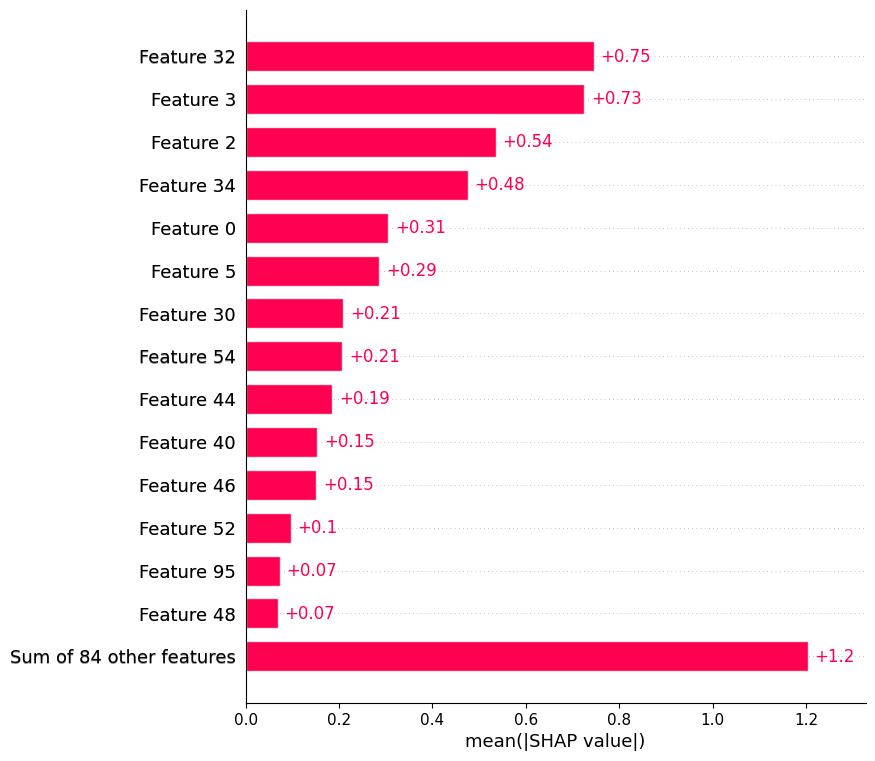

In [10]:
# Se recuperan el preprocesamiento y el modelo ya entrenados
transformer = pipe.named_steps["prep"]
model = pipe.named_steps["model"]

# Datos transformados: es lo que realmente ve el modelo
X_train_t = transformer.transform(X_train)
X_test_t = transformer.transform(X_test)
# Nombres de las columnas transformadas
feature_names = transformer.get_feature_names_out()

# Se explica una muestra de 500 personas de la prueba para que sea rápido
# Generador con semilla fija para repetir la muestra
rng = np.random.default_rng(42)
sample_n = min(500, X_test_t.shape[0])
sample_pos = rng.choice(X_test_t.shape[0], size=sample_n, replace=False)
X_shap = X_test_t[sample_pos]

# Explicador SHAP para modelos lineales
explainer = shap.LinearExplainer(model, X_train_t)
shap_values = explainer(X_shap)

print("Muestra SHAP:", X_shap.shape)
# Importancia global: promedio del aporte absoluto de cada variable
shap.plots.bar(shap_values, max_display=15)

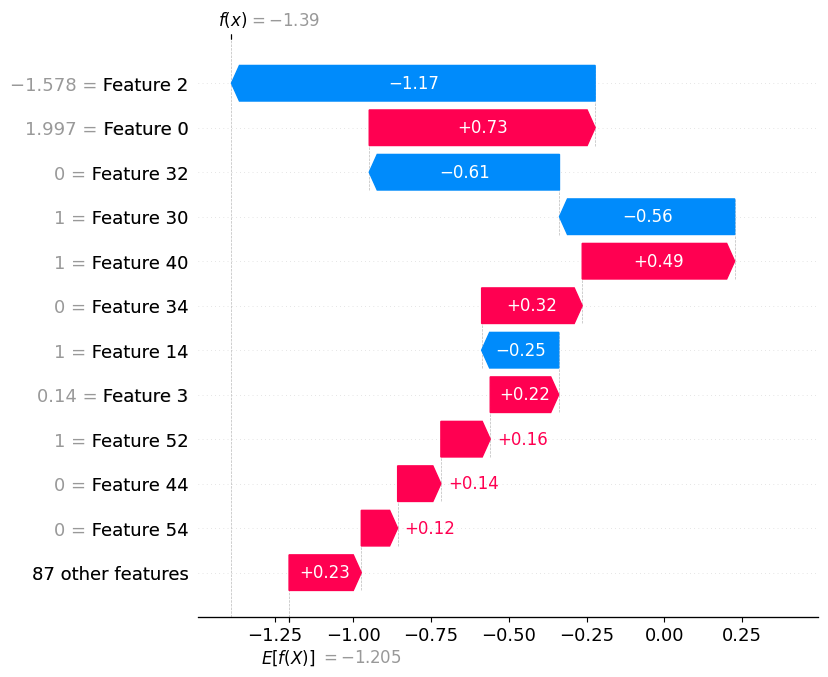

In [11]:
# Explicación local: cómo cada variable empuja la probabilidad de un caso concreto
case = 0
# Gráfico en cascada del primer caso de la muestra
shap.plots.waterfall(shap_values[case], max_display=12)

### Pregunta 6

¿Cuáles variables tienen mayor influencia global en las predicciones?

**Respuesta:**

Las variables con mayor influencia global son aquellas que presentan los valores SHAP absolutos más altos en promedio. Esto significa que son las variables que más contribuyen a los resultados del modelo. Para identificarlas, se revisa el gráfico de barras SHAP, que las ordena desde la de mayor influencia hasta la de menor influencia.

### Pregunta 7

Elija una predicción y explique qué variables aumentaron o redujeron la probabilidad estimada. No use lenguaje causal.

**Respuesta:**

Para explicar una predicción, se revisa el gráfico SHAP de cascada (*waterfall*) del caso seleccionado. Las variables con valores SHAP positivos contribuyeron a aumentar la probabilidad estimada por el modelo, mientras que las variables con valores negativos contribuyeron a reducirla. Esto permite entender cómo participó cada variable en el resultado, sin afirmar que sea la causa del nivel de ingresos de la persona.

# 7. Checklist académico de gobierno y cumplimiento

In [12]:
# Checklist académico de gobierno: cada control tiene un estado inicial por completar
checklist = pd.DataFrame([
    ["Finalidad","¿Está documentado para qué se usará el modelo?","No evidenciado",""],
    ["Minimización","¿Cada variable tiene una justificación de necesidad?","No evidenciado",""],
    ["Calidad","¿Hay reglas y resultados de calidad de datos?","Parcial","El notebook muestra nulos y limpieza."],
    ["Linaje","¿Puede seguirse fuente→transformación→modelo→salida?","Parcial","Pipeline reproducible en notebook."],
    ["Acceso","¿Están definidos roles y permisos sobre datos/modelo?","No evidenciado",""],
    ["Transparencia","¿Se documentan lógica, limitaciones y supervisión?","Parcial","Completar informe ejecutivo."],
    ["Auditoría de subgrupos","¿Se revisaron errores y tasas por grupos?","Cumple","Ver tabla de auditoría."],
    ["Supervisión humana","¿Existe responsable para revisar decisiones de alto impacto?","No evidenciado",""],
], columns=["control","pregunta","estado_inicial","evidencia"])
display(checklist)

,control,pregunta,estado_inicial,evidencia
0,Finalidad,¿Está documentado para qué se usará el modelo?,No evidenciado,
1,Minimización,¿Cada variable tiene una justificación de nece...,No evidenciado,
2,Calidad,¿Hay reglas y resultados de calidad de datos?,Parcial,El notebook muestra nulos y limpieza.
3,Linaje,¿Puede seguirse fuente→transformación→modelo→s...,Parcial,Pipeline reproducible en notebook.
4,Acceso,¿Están definidos roles y permisos sobre datos/...,No evidenciado,
5,Transparencia,"¿Se documentan lógica, limitaciones y supervis...",Parcial,Completar informe ejecutivo.
6,Auditoría de subgrupos,¿Se revisaron errores y tasas por grupos?,Cumple,Ver tabla de auditoría.
7,Supervisión humana,¿Existe responsable para revisar decisiones de...,No evidenciado,


Edite el checklist con uno de estos estados:

- **Cumple**
- **Parcial**
- **No evidenciado**
- **No aplica**

> Este checklist es **académico**. No constituye certificación legal.

In [20]:
checklist = pd.DataFrame([
    ["Finalidad",
     "¿Está documentado para qué se usará el modelo?",
     "Parcial",
     "Se indica que el modelo tiene una finalidad académica de clasificación y auditoría de sesgos."],

    ["Minimización",
     "¿Cada variable tiene una justificación de necesidad?",
     "Parcial",
     "Se excluyen sexo y raza del entrenamiento, pero falta justificar la necesidad de las demás variables."],

    ["Calidad",
     "¿Hay reglas y resultados de calidad de datos?",
     "Parcial",
     "El notebook muestra valores faltantes y aplica limpieza e imputación de datos."],

    ["Linaje",
     "¿Puede seguirse fuente→transformación→modelo→salida?",
     "Parcial",
     "Se identifica la fuente UCI y se documentan la limpieza, partición, transformación y entrenamiento."],

    ["Acceso",
     "¿Están definidos roles y permisos sobre datos/modelo?",
     "No evidenciado",
     "El notebook no muestra una configuración de usuarios, roles o permisos de acceso."],

    ["Transparencia",
     "¿Se documentan lógica, limitaciones y supervisión?",
     "Parcial",
     "Se utiliza regresión logística y SHAP para explicar las predicciones, pero falta documentar las limitaciones y la supervisión."],

    ["Auditoría de subgrupos",
     "¿Se revisaron errores y tasas por grupos?",
     "Cumple",
     "Se calcularon accuracy, recall, FPR y FNR por sexo y raza."],

    ["Supervisión humana",
     "¿Existe responsable para revisar decisiones de alto impacto?",
     "No evidenciado",
     "No se presenta un procedimiento ni un responsable definido para supervisar las decisiones del modelo."]
], columns=["control", "pregunta", "estado_inicial", "evidencia"])

display(checklist)

,control,pregunta,estado_inicial,evidencia
0,Finalidad,¿Está documentado para qué se usará el modelo?,Parcial,Se indica que el modelo tiene una finalidad ac...
1,Minimización,¿Cada variable tiene una justificación de nece...,Parcial,"Se excluyen sexo y raza del entrenamiento, per..."
2,Calidad,¿Hay reglas y resultados de calidad de datos?,Parcial,El notebook muestra valores faltantes y aplica...
3,Linaje,¿Puede seguirse fuente→transformación→modelo→s...,Parcial,Se identifica la fuente UCI y se documentan la...
4,Acceso,¿Están definidos roles y permisos sobre datos/...,No evidenciado,El notebook no muestra una configuración de us...
5,Transparencia,"¿Se documentan lógica, limitaciones y supervis...",Parcial,Se utiliza regresión logística y SHAP para exp...
6,Auditoría de subgrupos,¿Se revisaron errores y tasas por grupos?,Cumple,"Se calcularon accuracy, recall, FPR y FNR por ..."
7,Supervisión humana,¿Existe responsable para revisar decisiones de...,No evidenciado,No se presenta un procedimiento ni un responsa...


### Pregunta 8

¿Qué control no puede demostrarse solo con código y necesita evidencia organizacional adicional?

**Respuesta:**

La supervisión humana y el control de acceso son aspectos que no se pueden demostrar únicamente con el código. Se necesita evidencia de la organización, como documentos que indiquen quiénes son los responsables de revisar los resultados del modelo, quiénes tienen permiso para acceder a los datos y qué procedimientos se siguen para supervisar su uso. Esto permite asegurar que el modelo tenga un uso responsable y controlado.

# 8. Registro de hallazgos y plan de acción

In [13]:
# Registro de hallazgos: severidad, evidencia, acción, responsable y estado
hallazgos = pd.DataFrame(columns=[
    "hallazgo","severidad","evidencia","accion","responsable","estado"
])
# Fila de ejemplo que el estudiante reemplaza con sus propios hallazgos
hallazgos.loc[0] = [
    "Ejemplo: brecha de FNR entre subgrupos",
    "Por evaluar",
    "Tabla group_table / gap_df",
    "Revisar datos, umbral, variables proxy y proceso de supervisión",
    "Owner del modelo + negocio",
    "Abierto"
]
display(hallazgos)

,hallazgo,severidad,evidencia,accion,responsable,estado
0,Ejemplo: brecha de FNR entre subgrupos,Por evaluar,Tabla group_table / gap_df,"Revisar datos, umbral, variables proxy y proce...",Owner del modelo + negocio,Abierto


### Pregunta 9

¿Qué hallazgo impediría desplegar el modelo hasta ser resuelto?

**Respuesta:**

Un hallazgo que impediría desplegar el modelo sería encontrar diferencias importantes en las tasas de errores entre los grupos evaluados, especialmente si un grupo resulta más perjudicado que otro. Por ejemplo, la brecha de falsos positivos (FPR) entre hombres (28.72 %) y mujeres (8.44 %) es de 20.28 puntos porcentuales. Esta diferencia debe investigarse para identificar posibles sesgos y revisar las variables utilizadas antes de permitir que el modelo se use en decisiones reales.

### Pregunta 10

¿Qué evidencia conservaría para demostrar que el modelo fue auditado y revisado antes de su uso?

**Respuesta:**

Conservaría la documentación de la fuente de datos, las reglas de limpieza, el proceso de entrenamiento, las métricas generales y los resultados de la auditoría por sexo y raza. También guardaría los gráficos SHAP, las brechas identificadas, el checklist de gobierno, el registro de hallazgos y las acciones correctivas realizadas. Finalmente, conservaría la fecha de revisión y la aprobación de los responsables para demostrar que el modelo fue evaluado antes de su utilización.

# 9. Informe ejecutivo de auditoría
Responda en términos de negocio, con las cifras del notebook (máximo 12 líneas en total).


# 9. Informe ejecutivo de auditoría

**A. Desempeño global y métricas por subgrupo**

**Respuesta:** El modelo obtuvo una exactitud global de 80.12 %, un recall de 83.23 % y un F1 de 66.71 %. Sin embargo, la exactitud fue de 89.25 % en mujeres y 75.58 % en hombres, mostrando diferencias entre grupos.

**B. Principal brecha**

**Respuesta:** La principal brecha es la tasa de falsos positivos (FPR): 28.72 % en hombres y 8.44 % en mujeres, con una diferencia de 20.28 puntos porcentuales. Los grupos tienen 8,154 hombres y 4,057 mujeres.

**C. Explicabilidad SHAP**

**Respuesta:** SHAP global permite identificar las variables con mayor influencia en las predicciones, mientras que SHAP local muestra cómo las variables aumentan o reducen la predicción de una persona. No demuestra causalidad.

**D. Controles de gobierno**

**Respuesta:** Se revisó la auditoría por subgrupos y la calidad de los datos. Falta evidencia organizacional sobre los permisos de acceso y la supervisión humana.

**E. Limitación y recomendación**

**Respuesta:** El modelo presenta diferencias importantes entre grupos y requiere mayor evaluación. Se recomienda **aprobar con condiciones**, manteniendo supervisión humana y revisando las brechas antes de utilizarlo en decisiones reales.


# 10. Reto de aplicación y retroalimentación
Los cinco ejercicios operan sobre `X_model`, `audit`, `audit_result`, `proba`, `shap_values` y `checklist`. Cada respuesta escrita no debe exceder cuatro líneas.

In [14]:
# Objetos de trabajo para la sección de retos.
print("Variables del modelo:", X_model.shape)
print("Auditoría de prueba:", audit_result.shape)
print("Valores SHAP:", shap_values.values.shape)

Variables del modelo: (48842, 12)
Auditoría de prueba: (12211, 5)
Valores SHAP: (500, 98)


## Ejercicio 1 — Detección de variables proxy del sexo
En el Paso 3 se excluyó la variable sex del entrenamiento. Sin embargo, una exclusión solo es efectiva si ninguna otra variable reproduce la información retirada. En este ejercicio deberá comprobar numéricamente si relationship y marital-status, que el modelo sí recibe, permiten reconstruir el sexo de las personas.

**Se solicita:**
- Construir una tabla cruzada entre relationship y el sexo de la tabla de auditoría, normalizada por fila.
- Construir la misma tabla para marital-status.
- Identificar las categorías en que un solo sexo supera el 85 % de los casos.

In [21]:

# Ejercicio 1 — Detección de variables proxy del sexo

# 1. Tabla cruzada entre relationship y sexo
tabla_relationship = pd.crosstab(
    X["relationship"],
    audit["sex"],
    normalize="index"
) * 100

print("Tabla cruzada: relationship vs. sex (%)")
display(tabla_relationship.round(2))

# 2. Tabla cruzada entre marital-status y sexo
tabla_marital = pd.crosstab(
    X["marital-status"],
    audit["sex"],
    normalize="index"
) * 100

print("Tabla cruzada: marital-status vs. sex (%)")
display(tabla_marital.round(2))

# 3. Identificar categorías donde un sexo supera el 85 %
def identificar_proxy(tabla, variable):
    resultados = []

    for categoria, fila in tabla.iterrows():
        sexo_mayoritario = fila.idxmax()
        porcentaje = fila.max()

        if porcentaje > 85:
            resultados.append({
                "variable": variable,
                "categoria": categoria,
                "sexo_mayoritario": sexo_mayoritario,
                "porcentaje": round(porcentaje, 2)
            })

    return pd.DataFrame(resultados)

proxy_relationship = identificar_proxy(tabla_relationship, "relationship")
proxy_marital = identificar_proxy(tabla_marital, "marital-status")

# Unir los resultados
proxy_resultados = pd.concat(
    [proxy_relationship, proxy_marital],
    ignore_index=True
)

print("Categorías donde un sexo supera el 85 %:")
display(proxy_resultados)


Tabla cruzada: relationship vs. sex (%)


sex,Female,Male
relationship,,
Husband,0.01,99.99
Not-in-family,46.65,53.35
Other-relative,45.75,54.25
Own-child,44.53,55.47
Unmarried,76.64,23.36
Wife,99.87,0.13


Tabla cruzada: marital-status vs. sex (%)


sex,Female,Male
marital-status,,
Divorced,60.32,39.68
Married-AF-spouse,67.57,32.43
Married-civ-spouse,11.08,88.92
Married-spouse-absent,48.41,51.59
Never-married,44.79,55.21
Separated,60.85,39.15
Widowed,81.23,18.77


Categorías donde un sexo supera el 85 %:


,variable,categoria,sexo_mayoritario,porcentaje
0,relationship,Husband,Male,99.99
1,relationship,Wife,Female,99.87
2,marital-status,Married-civ-spouse,Male,88.92


### Pregunta 11

¿Qué variable funciona como proxy más fuerte del sexo y qué implica para la decisión de excluir sex del modelo?

**Respuesta:**

La variable **relationship** funciona como el proxy más fuerte del sexo, especialmente en las categorías `Husband`, donde el 99.99 % son hombres, y `Wife`, donde el 99.87 % son mujeres. Esto demuestra que, aunque se elimine la variable `sex` del entrenamiento, el modelo todavía puede obtener información relacionada con ella a través de otras variables. Por lo tanto, excluir `sex` no garantiza eliminar el posible sesgo y es necesario evaluar también las variables que pueden actuar como proxies.

## Ejercicio 2 — Efecto del umbral de decisión sobre las brechas
El modelo base clasifica como positivo a quien supera una probabilidad de 0,50. Ese umbral no es un dato técnico neutral, sino una decisión de negocio que redistribuye los errores entre los grupos. Corresponde medir cómo cambian las brechas por sexo al mover el umbral.

**Se solicita:**
- Recalcular las predicciones con umbrales de 0,30, 0,50 y 0,70.
- Obtener, para cada umbral, el FNR y el FPR de mujeres y de hombres con la función group_metrics.
- Construir las columnas brecha_fnr y brecha_fpr y presentar los resultados en una tabla.

In [23]:
# Umbrales que vamos a evaluar
umbrales = [0.30, 0.50, 0.70]

resultados = []

for umbral in umbrales:
    # Recalcular predicciones según el umbral usando la variable correcta 'proba'
    y_pred_umbral = (proba >= umbral).astype(int)

    # Crear un DataFrame temporal para cumplir con la estructura requerida por group_metrics
    temp_audit = audit_test.copy()
    temp_audit["y_true"] = y_test
    temp_audit["y_pred"] = y_pred_umbral

    # Calcular métricas por sexo usando el DataFrame temporal
    metricas = group_metrics(temp_audit, "sex")

    # Obtener las métricas de mujeres y hombres
    mujeres = metricas[metricas["group"] == "Female"].iloc[0]
    hombres = metricas[metricas["group"] == "Male"].iloc[0]

    # Calcular las brechas absolutas entre grupos
    brecha_fnr = abs(hombres["fnr"] - mujeres["fnr"])
    brecha_fpr = abs(hombres["fpr"] - mujeres["fpr"])

    resultados.append({
        "umbral": umbral,
        "FNR_mujeres": mujeres["fnr"],
        "FNR_hombres": hombres["fnr"],
        "FPR_mujeres": mujeres["fpr"],
        "FPR_hombres": hombres["fpr"],
        "brecha_fnr": brecha_fnr,
        "brecha_fpr": brecha_fpr
    })

# Crear y mostrar la tabla final
tabla_umbral = pd.DataFrame(resultados)

display(tabla_umbral.round(4))

,umbral,FNR_mujeres,FNR_hombres,FPR_mujeres,FPR_hombres,brecha_fnr,brecha_fpr
0,0.3,0.1545,0.0502,0.1615,0.4355,0.1043,0.2740
1,0.5,0.2914,0.1450,0.0844,0.2872,0.1464,0.2029
2,0.7,0.4371,0.3196,0.0366,0.1321,0.1175,0.0955


**Pregunta 12.** ¿Existe un umbral que elimine a la vez las brechas de FNR y de FPR? ¿Quién debería decidir el umbral final?

**Respuesta:**

No existe un umbral que elimine simultáneamente las brechas de FNR y FPR. En los tres umbrales evaluados, ambas brechas siguen siendo distintas de cero.

- Con **0,30**, la brecha de FNR es 0,4355 y la de FPR es 0,1043.
- Con **0,50**, la brecha de FNR es 0,1464 y la de FPR es 0,2029.
- Con **0,70**, la brecha de FNR es 0,1321 y la de FPR es 0,0955.

El umbral de **0,70** presenta las menores brechas de ambas métricas entre las tres alternativas evaluadas, pero no las elimina.

El umbral final debería decidirlo la organización, con participación de las áreas responsables del negocio, especialistas técnicos y responsables de ética, cumplimiento y gobernanza de datos. La decisión debe considerar el impacto de los errores en cada grupo, el propósito del modelo y los riesgos para las personas afectadas. No debería elegirse únicamente por conveniencia técnica ni para mejorar una sola métrica. También debe documentarse y revisarse periódicamente.

## Ejercicio 3 — Nueva dimensión de auditoría: grupos de edad
La auditoría de la Actividad 2 se limitó al sexo y a la raza. Un comité de gobierno, sin embargo, suele pedir otras dimensiones de riesgo. La edad es una de ellas: un modelo puede dejar sistemáticamente fuera a los clientes jóvenes, aun cuando la variable age forme parte legítima del modelo.

**Se solicita:**
- Crear la columna grupo_edad en audit_result con los tramos 17-29, 30-49 y 50+.
- Aplicar group_metrics a la nueva dimensión.
- Calcular con gap_report la brecha de FNR y la de tasa positiva predicha.

In [25]:
# Recuperar la edad de la variable original X usando el índice de prueba
audit_result["age"] = X.loc[audit_result.index, "age"]

# Crear los grupos de edad en audit_result
audit_result["grupo_edad"] = pd.cut(
    audit_result["age"],
    bins=[16, 29, 49, float("inf")],
    labels=["17-29", "30-49", "50+"]
)

# Calcular las métricas por grupo de edad
metricas_edad = group_metrics(audit_result, "grupo_edad")

print("Métricas por grupo de edad:")
display(metricas_edad)

# Calcular las brechas de cada métrica usando gap_report para la dimensión grupo_edad
resultados_brechas = []
for metric in ["positive_rate_pred", "recall", "fpr", "fnr"]:
    r = gap_report(metricas_edad, metric)
    if r:
        r["dimension"] = "grupo_edad"
        resultados_brechas.append(r)

brechas_edad = pd.DataFrame(resultados_brechas)

print("Brechas por grupo de edad:")
display(brechas_edad)

# Mostrar específicamente las brechas solicitadas (FNR y tasa positiva predicha)
display(
    brechas_edad[
        brechas_edad["metric"].isin(["fnr", "positive_rate_pred"])
    ]
)

Métricas por grupo de edad:


,dimension,group,n,positive_rate_pred,accuracy,recall,fpr,fnr
0,grupo_edad,17-29,3663,0.097461,0.923287,0.713483,0.065997,0.286517
1,grupo_edad,30-49,5868,0.438480,0.768234,0.826602,0.258788,0.173398
2,grupo_edad,50+,2680,0.536940,0.706716,0.868095,0.373118,0.131905


Brechas por grupo de edad:


,metric,max_group,max_value,min_group,min_value,gap,dimension
0,positive_rate_pred,50+,0.536940,17-29,0.097461,0.439479,grupo_edad
1,recall,50+,0.868095,17-29,0.713483,0.154612,grupo_edad
2,fpr,50+,0.373118,17-29,0.065997,0.307121,grupo_edad
3,fnr,17-29,0.286517,50+,0.131905,0.154612,grupo_edad


,metric,max_group,max_value,min_group,min_value,gap,dimension
0,positive_rate_pred,50+,0.536940,17-29,0.097461,0.439479,grupo_edad
3,fnr,17-29,0.286517,50+,0.131905,0.154612,grupo_edad


**Pregunta 13.** ¿Qué grupo de edad resulta más afectado por los falsos negativos y qué tamaño tiene?

**Respuesta:**

El grupo de edad más afectado por los falsos negativos es el de **17 a 29 años**, porque presenta el FNR más alto, de **0,2865 (28,65 %)**. Esto significa que aproximadamente el 28,65 % de las personas de ese grupo que realmente tienen ingresos superiores a 50K son clasificadas incorrectamente como negativas.

Este grupo tiene un tamaño de **3.663 personas**.

En comparación, el grupo de 50 años o más presenta un FNR de 13,19 %, mientras que el grupo de 30 a 49 años tiene un FNR de 17,34 %.

## Ejercicio 4 — Importancia SHAP agregada por variable original
El gráfico SHAP del Paso 7 muestra columnas transformadas: cada categoría de una variable aparece por separado. Esa fragmentación puede subestimar el peso real de una variable categórica con muchas categorías. Corresponde agregar la importancia de cada columna one-hot a su variable original.

**Se solicita:**
- Calcular el promedio del valor SHAP absoluto de cada columna transformada.
- Asignar cada columna a su variable original.
- Sumar la importancia por variable original y ordenarla de mayor a menor.

In [26]:
# Calcular el promedio del valor SHAP absoluto por columna transformada
importancias = np.abs(shap_values.values).mean(axis=0)

# Crear un DataFrame con las columnas transformadas y su importancia
df_shap = pd.DataFrame({
    "feature_transformada": feature_names,
    "importancia": importancias
})

# Asignar cada columna transformada a su variable original
def obtener_variable_original(nombre):
    nombre = nombre.replace("num__", "").replace("cat__", "")

    # Las variables categóricas tienen el prefijo de su nombre
    variables = [
        "age", "workclass", "fnlwgt", "education",
        "education-num", "marital-status", "occupation",
        "relationship", "capital-gain", "capital-loss",
        "hours-per-week", "native-country"
    ]

    for variable in sorted(variables, key=len, reverse=True):
        if nombre == variable or nombre.startswith(variable + "_"):
            return variable

    return nombre

df_shap["variable_original"] = (
    df_shap["feature_transformada"].apply(obtener_variable_original)
)

# Sumar las importancias de las columnas de cada variable original
importancia_original = (
    df_shap.groupby("variable_original")["importancia"]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

# Mostrar el resultado ordenado de mayor a menor
print("Importancia SHAP agregada por variable original:")
display(importancia_original.round(4))

Importancia SHAP agregada por variable original:


,variable_original,importancia
0,marital-status,1.5703
1,occupation,0.8162
2,capital-gain,0.7250
3,education-num,0.5364
4,relationship,0.4647
5,age,0.3060
6,hours-per-week,0.2865
7,education,0.2344
8,workclass,0.2141
9,native-country,0.1880


**Pregunta 14.** ¿Qué variable original concentra mayor importancia y qué relación tiene con el hallazgo del Ejercicio 1?

**Respuesta:**

La variable original que concentra la mayor importancia SHAP es **marital-status**, con un valor de **1,5703**, por encima de occupation (0,8162) y capital-gain (0,7250).

Este resultado se relaciona con el hallazgo del Ejercicio 1, donde observamos que algunas variables pueden actuar como *proxies* o indicadores indirectos de características sensibles. En particular, `marital-status` mostró una asociación importante con el sexo: la categoría `Married-civ-spouse` estaba compuesta en un 88,92 % por hombres.

Por lo tanto, aunque el sexo fue excluido directamente del modelo, `marital-status` podría aportar información indirecta relacionada con esta característica. Esto representa un posible riesgo de sesgo que debe analizarse mediante auditorías adicionales.

Es importante recordar que la importancia SHAP muestra la influencia de una variable en las predicciones, pero no demuestra por sí sola una relación causal ni la existencia de discriminación.

## Ejercicio 5 — Checklist con base normativa y estado final
El checklist del Paso 8 enumera controles, pero no indica qué norma o marco sustenta cada uno. Un comité necesita esa trazabilidad para priorizar. En este ejercicio deberá vincular cada control con su base normativa y asignar un estado final sustentado en la evidencia obtenida.

**Se solicita:**
- Agregar la columna base_normativa (Ley 29733 y DS 016-2024-JUS, Ley 31814 y DS 115-2025-PCM o DAMA-DMBOK).
- Agregar la columna estado_final con los estados Cumple, Parcial, No evidenciado o No aplica.
- Contar los controles por estado final.

In [27]:
# Definir la base normativa y el estado final de cada control
base_normativa = {
    "Finalidad": "Ley 31814 y DS 115-2025-PCM",
    "Minimización": "Ley 29733 y DS 016-2024-JUS",
    "Calidad": "DAMA-DMBOK y Ley 31814",
    "Linaje": "DAMA-DMBOK",
    "Acceso": "Ley 29733 y DS 016-2024-JUS",
    "Transparencia": "Ley 31814 y DS 115-2025-PCM",
    "Auditoría de subgrupos": "Ley 31814 y DS 115-2025-PCM; DAMA-DMBOK",
    "Supervisión humana": "Ley 31814 y DS 115-2025-PCM"
}

estado_final = {
    "Finalidad": "Parcial",
    "Minimización": "Parcial",
    "Calidad": "Parcial",
    "Linaje": "Parcial",
    "Acceso": "No evidenciado",
    "Transparencia": "Parcial",
    "Auditoría de subgrupos": "Cumple",
    "Supervisión humana": "No evidenciado"
}

# Incorporar las nuevas columnas al checklist existente
checklist["base_normativa"] = checklist["control"].map(base_normativa)
checklist["estado_final"] = checklist["control"].map(estado_final)

# Mostrar el checklist actualizado
print("Checklist con base normativa y estado final:")
display(checklist)

# Contar los controles por estado final
conteo_estados = (
    checklist["estado_final"]
    .value_counts()
    .reindex(
        ["Cumple", "Parcial", "No evidenciado", "No aplica"],
        fill_value=0
    )
    .reset_index()
)

conteo_estados.columns = ["estado_final", "cantidad"]

print("Cantidad de controles por estado final:")
display(conteo_estados)

Checklist con base normativa y estado final:


,control,pregunta,estado_inicial,evidencia,base_normativa,estado_final
0,Finalidad,¿Está documentado para qué se usará el modelo?,Parcial,Se indica que el modelo tiene una finalidad ac...,Ley 31814 y DS 115-2025-PCM,Parcial
1,Minimización,¿Cada variable tiene una justificación de nece...,Parcial,"Se excluyen sexo y raza del entrenamiento, per...",Ley 29733 y DS 016-2024-JUS,Parcial
2,Calidad,¿Hay reglas y resultados de calidad de datos?,Parcial,El notebook muestra valores faltantes y aplica...,DAMA-DMBOK y Ley 31814,Parcial
3,Linaje,¿Puede seguirse fuente→transformación→modelo→s...,Parcial,Se identifica la fuente UCI y se documentan la...,DAMA-DMBOK,Parcial
4,Acceso,¿Están definidos roles y permisos sobre datos/...,No evidenciado,El notebook no muestra una configuración de us...,Ley 29733 y DS 016-2024-JUS,No evidenciado
5,Transparencia,"¿Se documentan lógica, limitaciones y supervis...",Parcial,Se utiliza regresión logística y SHAP para exp...,Ley 31814 y DS 115-2025-PCM,Parcial
6,Auditoría de subgrupos,¿Se revisaron errores y tasas por grupos?,Cumple,"Se calcularon accuracy, recall, FPR y FNR por ...",Ley 31814 y DS 115-2025-PCM; DAMA-DMBOK,Cumple
7,Supervisión humana,¿Existe responsable para revisar decisiones de...,No evidenciado,No se presenta un procedimiento ni un responsa...,Ley 31814 y DS 115-2025-PCM,No evidenciado


Cantidad de controles por estado final:


,estado_final,cantidad
0,Cumple,1
1,Parcial,5
2,No evidenciado,2
3,No aplica,0


**Pregunta 15.** ¿Cuántos controles quedan como No evidenciado y qué acción concreta propone para cada uno?

**Respuesta:**

Quedan **2 controles como No evidenciado**: Acceso y Supervisión humana.

1. **Acceso:** Definir roles y permisos para las personas que pueden consultar, modificar o administrar los datos y el modelo. También se deben documentar los mecanismos de autenticación y control de acceso para proteger la información.

2. **Supervisión humana:** Designar a una persona o equipo responsable de revisar las predicciones del modelo, establecer un procedimiento para evaluar posibles errores o sesgos y permitir que las decisiones automatizadas puedan ser revisadas por una persona.

Estas acciones permitirían fortalecer la gobernanza del modelo, proteger los datos personales y asegurar que sus resultados no se utilicen sin controles adecuados.

# 11. Retroalimentación final — DAMA-DMBOK y marco normativo

**Pregunta 16.** A partir de lo realizado, identifique qué áreas de conocimiento de DAMA-DMBOK se evidencian directamente en este laboratorio. Justifique en un máximo de tres líneas.

**Respuesta:**

Las áreas de DAMA-DMBOK que se evidencian directamente son **Calidad de Datos**, por la identificación de valores faltantes y su tratamiento; **Gobierno de Datos**, mediante el checklist de controles y responsabilidades; y **Metadatos y Linaje**, al documentar la fuente UCI, las transformaciones y el proceso de entrenamiento del modelo.


**Pregunta 17.** Ley 29733 y DS 016-2024-JUS. ¿Qué datos del caso tendrían la condición de datos sensibles y qué obligación deriva de ello?

**Respuesta:**

En este caso, el dato de **raza** tiene la condición de dato sensible por revelar el origen racial o étnico. Además, la información sobre **ingresos económicos** también está comprendida en la categoría de datos sensibles según la Ley 29733. Por ello, su tratamiento requiere cumplir las condiciones legales correspondientes, como contar con el consentimiento válido y, cuando corresponda, expreso y por escrito, respetar la finalidad informada y aplicar medidas de seguridad adecuadas.


**Pregunta 18.** Ley 31814 y DS 115-2025-PCM. ¿En qué nivel de riesgo ubicaría el uso del modelo y qué control sería indispensable antes de desplegarlo?

**Respuesta:**

Si el modelo se utilizara para tomar decisiones que afecten oportunidades económicas o el acceso a servicios, lo ubicaría como un sistema de **riesgo alto**, sujeto a la evaluación de su uso concreto. Antes de desplegarlo sería indispensable realizar una evaluación de riesgos e impactos, corregir o mitigar las brechas detectadas entre grupos y establecer **supervisión humana efectiva**, para que ninguna decisión importante dependa exclusivamente de la predicción automatizada.

# 12. Conclusiones

1. La auditoría permitió identificar diferencias importantes en el desempeño del modelo entre grupos de sexo y edad. En particular, las personas de 17 a 29 años presentan una mayor tasa de falsos negativos, mientras que también se observaron brechas de FPR entre hombres y mujeres.

2. El análisis SHAP mostró que `marital-status` es la variable con mayor importancia agregada. Además, se identificaron variables como `relationship` y `marital-status` que pueden actuar como proxies de características sensibles, aunque el sexo y la raza fueron excluidos directamente del entrenamiento.

3. El modelo no debería desplegarse sin controles adicionales. Es necesario fortalecer la protección de datos, definir responsables de supervisión humana, revisar las brechas entre grupos y documentar las decisiones para garantizar un uso responsable, transparente y justo.

# 13. Checklist de entrega

- [x] UCI Adult ID 2 visible.
- [x] Ficha de datos y linaje.
- [x] Variables sensibles separadas para auditoría.
- [x] Train/test reproducible.
- [x] Métricas globales y por sexo y raza.
- [x] Brechas cuantificadas.
- [x] SHAP global y local.
- [x] Checklist de gobierno/cumplimiento.
- [x] Registro de hallazgos.
- [x] Informe ejecutivo.
- [x] Cinco retos resueltos.
- [x] No se usa SHAP como causalidad.
- [x] No se presenta el notebook como certificación legal.
- [x] Enlaces de Colab y GitHub enviados.

# Referencias
- UCI Machine Learning Repository — Adult, ID 2.
- DAMA International — DAMA-DMBOK, 2.ª ed. revisada.
- Molnar, C. — *Interpretable Machine Learning*.
- Sílabo Analítica Empresarial Integrada — TECSUP 2026-II.